## Setup (run this first)
This cell finds the project files automatically: current folder, then the group GitHub repo, then a shared Drive folder, then a zip upload. Everyone (group members and the instructor) can run it without editing paths.

In [1]:
# ---- Setup: works for any group member, the instructor, Colab or a laptop ------------------------------
# Order tried: (1) the files are already in the current folder, (2) Member3_Baseline_NLP.zip is already uploaded
# (Colab file panel or next to this notebook), (3) the shared Google Drive zip (downloaded, no sign-in),
# (4) the group GitHub repo, (5) an already-mounted Drive folder, (6) you upload the zip when asked. Nothing needs editing.
import os, sys, glob, zipfile, subprocess
REPO_URL = os.environ.get("REPO_URL", "https://github.com/jijjira/anlp-at2b-study-to-career.git")
DRIVE_DIR = "/content/drive/MyDrive/ANLP AT2B"
DRIVE_ZIP_ID = "1pgnI7O_CHeXK7RRtrGqA-XA7dKOvW6G_"   # Member3_Baseline_NLP.zip in the shared Drive folder
NEEDED = ["skill_extractor.py", "skill_extractor_v2.py", "analysis.py", "evaluate.py", "gold_annotations.py",
          "job_cleaned.csv", "skills_dictionary.csv", "normalisation.py", "extra_aliases_reviewed.csv",
          "discovery_candidates_raw.csv", "gold_split.json"]
try:
    import google.colab; IN_COLAB = True
except ImportError:
    IN_COLAB = False
def have_all(d="."): return all(os.path.exists(os.path.join(d, f)) for f in NEEDED)
def use(folder): os.chdir(folder); print("Using folder:", os.getcwd())
def code_folder(root):
    hits = glob.glob(os.path.join(root, "**", "skill_extractor_v2.py"), recursive=True)
    return os.path.dirname(hits[0]) if hits else None
def from_zip(z):
    out = "/content/m3" if IN_COLAB else os.path.join(os.path.dirname(os.path.abspath(z)), "_m3")
    zipfile.ZipFile(z).extractall(out); f = code_folder(out)
    if f: use(f)
START = os.getcwd()
if not have_all():                                   # (2) a zip that is already there
    for z in glob.glob("*.zip") + glob.glob("/content/*.zip"):
        if "Member3" in os.path.basename(z) and not have_all(): from_zip(z)
if not have_all():                                   # (3) the public Drive zip (one file, no sign-in needed)
    try:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gdown"], check=False)
        import gdown
        zdir = "/content" if IN_COLAB else START
        zp = gdown.download(id=DRIVE_ZIP_ID, output=os.path.join(zdir, "Member3_Baseline_NLP.zip"), quiet=True)
        if zp and zipfile.is_zipfile(zp): from_zip(zp)
        else: print("Could not download the zip from Drive, trying the next option.")
    except Exception:
        print("Could not download the zip from Drive, trying the next option.")
if not have_all():                                   # (4) group repo (works only if it is public or you are signed in)
    dest = "/content/_repo" if IN_COLAB else os.path.join(START, "_repo")
    if not os.path.exists(dest):
        env = dict(os.environ, GIT_TERMINAL_PROMPT="0")
        r = subprocess.run(["git", "clone", "--depth", "1", REPO_URL, dest], capture_output=True, text=True, env=env)
        if r.returncode != 0: print("Could not clone the repo (it may be private), trying the next option.")
    f = code_folder(dest) if os.path.exists(dest) else None
    if f: use(f)
if not have_all() and os.path.isdir(DRIVE_DIR) and have_all(DRIVE_DIR): use(DRIVE_DIR)   # (5) Drive, only if already mounted
if not have_all() and IN_COLAB:                      # (6) ask for the zip; never save into the Drive mount
    os.chdir("/content")
    print("Please choose Member3_Baseline_NLP.zip (from the group Drive or the submission).")
    from google.colab import files
    for name in files.upload():
        if name.endswith(".zip") and not have_all(): from_zip(os.path.join("/content", name))
sys.path.insert(0, os.getcwd())
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "spacy", "pymupdf", "reportlab"], check=False)
missing = [f for f in NEEDED if not os.path.exists(f)]
print("Working folder:", os.getcwd()); print("Missing files:", missing if missing else "none, good to go")


Working folder: .../step3_baseline_nlp
Missing files: none, good to go


# Step 3, Baseline Skill Extraction (spaCy PhraseMatcher)

**Project:** From Australian Study Materials to U.S. Career Opportunities  
**Inputs:** `job_cleaned.csv` (Step 1), `skills_dictionary.csv` and `normalisation.py` (Step 2)  
**Output:** `job_skills_extracted.csv` → `job_id | career_category | job_title | extracted_skills`

Pipeline: `job_description → preprocess → spaCy tokenise → PhraseMatcher (aliases) → canonical skill (normalise_skill) → de-duplicate per job`

The logic lives in `skill_extractor.py` so the **same `extract_skills(text)`** can later be applied to student study material.

In [2]:
import pandas as pd
from skill_extractor import SkillExtractor, extract_skills

jobs = pd.read_csv("job_cleaned.csv", encoding="utf-8-sig")
print(len(jobs), "jobs"); jobs[["job_id","career_category","job_title"]].head()

688 jobs


,job_id,career_category,job_title
0,Greenhouse:5507088002,Data Scientist,Staff Data Scientist
1,Greenhouse:4006735005,ML Engineer,"Machine Learning Engineer, Search Quality"
2,Greenhouse:6322654002,Data Engineer,"Sr. Product Manager, Data Engineering"
3,Greenhouse:6485460002,ML Engineer,Machine Learning Research Engineer
4,Greenhouse:4738660,Data Engineer,"Senior Software Engineer, Data Engineering"


## 1. Matching design
* **Tokenizer-only spaCy** (`spacy.blank("en")`); no statistical model is needed for dictionary matching.
* Ordinary aliases use `PhraseMatcher(attr="LOWER")` (case-insensitive). The alias `R` uses `attr="ORTH"` (case-sensitive) so a lowercase *r* never fires, and tokenisation stops `R&D` from matching.
* Aliases and job text go through the same `preprocess()` (unicode hyphens, trademark signs, `/`, commas glued to words, sentence-final dots), so both are tokenised identically.
* The matched **alias** is mapped with `normalise_skill()` from `normalisation.py`. At start-up the extractor asserts the CSV and `normalisation.py` agree.
* Skills are de-duplicated per job and kept in order of first appearance.
* All alias hits are kept by default (`resolve_overlaps=False`), e.g. “AWS Lambda” yields AWS Lambda and AWS, the same convention as the Step 2 frequency tables.

In [3]:
ext = SkillExtractor()
demo = "Strong Python and SQL; we deploy ML models and LLMs on Amazon Web Services (CI/CD, k8s). AI R&D team."
for m in ext.extract_with_evidence(demo): print(f"{m.text!r:25} alias={m.alias!r:25} -> {m.canonical}")
print(extract_skills(demo))

'Python'                  alias='python'                  -> Python
'SQL'                     alias='sql'                     -> SQL
'ML models'               alias='ml models'               -> Machine Learning
'LLMs'                    alias='llms'                    -> Large Language Models
'Amazon Web Services'     alias='amazon web services'     -> AWS
'CI / CD'                 alias='ci/cd'                   -> CI/CD
'k8s'                     alias='k8s'                     -> Kubernetes


['Python', 'SQL', 'Machine Learning', 'Large Language Models', 'AWS', 'CI/CD', 'Kubernetes']


## 2. Run on all job advertisements

In [4]:
rows, long_rows = [], []
all_matches = ext.extract_many(jobs["job_description"].fillna(""))
for job, matches in zip(jobs.itertuples(index=False), all_matches):
    skills = ext._dedupe(matches)
    rows.append({"job_id": job.job_id, "career_category": job.career_category,
                 "job_title": job.job_title, "extracted_skills": ", ".join(skills)})
    for s in skills:
        hits = [m for m in matches if m.canonical == s]
        long_rows.append({"job_id": job.job_id, "career_category": job.career_category,
                          "canonical_skill": s, "skill_category": ext.alias_to_category[s],
                          "first_alias_matched": hits[0].alias, "mention_count": len(hits)})
job_skills = pd.DataFrame(rows); job_skills_long = pd.DataFrame(long_rows)
job_skills.to_csv("job_skills_extracted.csv", index=False, encoding="utf-8-sig")
job_skills_long.to_csv("job_skills_long.csv", index=False, encoding="utf-8-sig")
job_skills.head(10)

,job_id,career_category,job_title,extracted_skills
0,Greenhouse:5507088002,Data Scientist,Staff Data Scientist,"Databricks, Apache Spark, Recommendation Syste..."
1,Greenhouse:4006735005,ML Engineer,"Machine Learning Engineer, Search Quality","Large Language Models, APIs, Knowledge Graphs,..."
2,Greenhouse:6322654002,Data Engineer,"Sr. Product Manager, Data Engineering","Databricks, Data Warehousing, Machine Learning..."
3,Greenhouse:6485460002,ML Engineer,Machine Learning Research Engineer,"Machine Learning, APIs, PyTorch, JAX, TensorFlow"
4,Greenhouse:4738660,Data Engineer,"Senior Software Engineer, Data Engineering","Machine Learning, Data Pipelines, Data Lake, D..."
5,Greenhouse:6558007002,Data Engineer,Data Engineer,"Data Analysis, Python, SQL, Pandas"
6,Ashby:e91eb4bc-93bf-4e3a-b7c9-4a2f506df43f,AI Engineer,AI Product Engineer,"Large Language Models, TypeScript, Python, Vec..."
7,Ashby:fc5bbc77-a30c-4e7a-9acc-8a2e748545b4,Data Engineer,Data Engineer,"Data Pipelines, Data Warehousing, Python, Scal..."
8,Greenhouse:7069793002,Data Scientist,Staff Data Scientist - Infrastructure,"Databricks, Apache Spark, Machine Learning, Py..."
9,Greenhouse:5601881,Data Analyst,Data Analyst,"Data Pipelines, Dashboarding, SQL, Apache Spar..."


## 3. Summary

In [5]:
job_skills["n_skills"] = job_skills["extracted_skills"].map(lambda s: len([x for x in s.split(", ") if x]))
print("Jobs with no skill matched:", (job_skills.n_skills == 0).sum())
print(job_skills.groupby("career_category")["n_skills"].agg(["count","mean","median","max"]).round(1))
top = job_skills_long.groupby("canonical_skill")["job_id"].nunique().sort_values(ascending=False)
(top.head(15) / len(jobs) * 100).round(1).rename("% of jobs")

Jobs with no skill matched: 6
                 count  mean  median  max
career_category                          
AI Engineer        275   6.8     6.0   24
Data Analyst        27   9.8     9.0   18
Data Engineer       57  10.7    10.0   25
Data Scientist     127   8.3     8.0   24
ML Engineer        202   9.8     9.0   28


canonical_skill
Python                     66.3
Large Language Models      46.7
Machine Learning           42.4
SQL                        34.7
APIs                       25.0
Statistics                 20.2
Data Pipelines             19.5
Distributed Systems        18.0
Artificial Intelligence    17.9
Apache Spark               17.7
PyTorch                    16.4
Generative AI              16.3
AWS                        16.0
Dashboarding               15.4
Kubernetes                 15.1
Name: % of jobs, dtype: float64

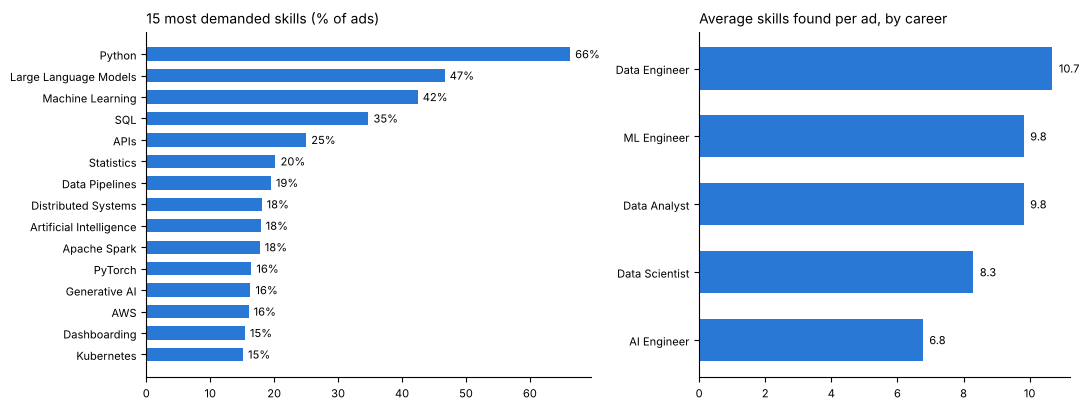

In [6]:
import os, matplotlib.pyplot as plt
os.makedirs("figures", exist_ok=True)
BLUE, INK = "#2a78d6", "#0b0b0b"
share = (top.head(15) / len(jobs) * 100).iloc[::-1]
by_car = job_skills.groupby("career_category")["n_skills"].mean().sort_values()
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.2, 1]})
a.barh(share.index, share.values, color=BLUE, height=0.62)
for y, v in enumerate(share.values): a.text(v + 0.8, y, f"{v:.0f}%", va="center", fontsize=8)
a.set_title("15 most demanded skills (% of ads)", loc="left", fontsize=10); a.tick_params(labelsize=8)
b.barh(by_car.index, by_car.values, color=BLUE, height=0.62)
for y, v in enumerate(by_car.values): b.text(v + 0.2, y, f"{v:.1f}", va="center", fontsize=8)
b.set_title("Average skills found per ad, by career", loc="left", fontsize=10); b.tick_params(labelsize=8)
for ax in (a, b):
    for sp in ["top", "right"]: ax.spines[sp].set_visible(False)
plt.tight_layout(); fig.savefig("figures/fig0_baseline_skill_demand.png", dpi=300, bbox_inches="tight"); plt.show()

## 4. Validation against Step 2

Step 2 counted aliases with regular expressions. Comparing job-level results per canonical skill (set equality) shows the two methods agree on 127 of 132 skills; every difference was inspected:

| Skill | Step 2 regex | spaCy | Reason |
|---|---|---|---|
| R | 60 | 51 | Regex matched **R&D** (9 jobs), a false positive; spaCy tokenises `R&D` as one token |
| GitHub | 40 | 39 | Regex matched a `github.com/...` **URL**, not a skill mention |
| CI/CD | 90 | 92 | `CI / CD` written with spaces |
| Fine-tuning | 83 | 85 | Non-breaking hyphen (U+2011) in the text |
| Time Series | 17 | 18 | Non-breaking hyphen (U+2011) in the text |

So the Step 2 frequency for **R** is inflated (8.7% → 7.4% of jobs).

In [7]:
import re
sd = pd.read_csv("skills_dictionary.csv")
def pat(a):
    return re.compile(r"(?<![A-Za-z0-9])R(?![A-Za-z0-9])") if a == "R" else re.compile(rf"(?<![A-Za-z0-9]){re.escape(a)}(?![A-Za-z0-9])", re.I)
spacy_sets = {c: set(g.job_id) for c, g in job_skills_long.groupby("canonical_skill")}
diffs = []
for c, g in sd.groupby("canonical_skill"):
    ps = [pat(a) for a in g.alias]
    rx = set(jobs.loc[jobs.job_description.map(lambda t: any(p.search(t) for p in ps)), "job_id"])
    sp = spacy_sets.get(c, set())
    if rx != sp: diffs.append({"skill": c, "step2_regex": len(rx), "spacy": len(sp), "only_regex": len(rx-sp), "only_spacy": len(sp-rx)})
print("Skills where methods differ:", len(diffs), "of", sd.canonical_skill.nunique())
pd.DataFrame(diffs)

Skills where methods differ: 5 of 132


,skill,step2_regex,spacy,only_regex,only_spacy
0,CI/CD,90,92,0,2
1,Fine-tuning,83,85,0,2
2,GitHub,40,39,1,0
3,R,60,51,9,0
4,Time Series,17,18,0,1


## 5. Known limitations (baseline)
* **Exact-phrase only**: paraphrases (“building predictive models”) are not found, that is what the Sentence-Transformer method (Member 4) addresses.
* **Ambiguous aliases**: lowercase `spark` also matches the verb in one boilerplate sentence (“spark innovation”) in 6 jobs. `Spark`/`Jax`/`Git` etc. are otherwise real mentions in the sample checked.
* **Missing aliases**: abbreviations such as `ML`, `AI`, `DL`, `K8s` variants and `Scikit` are not in the Step 2 dictionary, so they are not extracted (Step 2's own check shows `ML` is not normalised).
* Overlapping hits are all kept (e.g. SQL Server also yields SQL); set `resolve_overlaps=True` for longest-match-only.
* Frequencies are mentions in advertisements, not measures of candidate mastery or hiring probability.